# 📝 Practical Exam: Exploratory Data Analysis & Financial Risk Modeling

### Part 1: Empirical Analysis (EDA)
Using `yfinance`, download the daily closing prices (`Close`) for **Microsoft (`MSFT`)** and **Goldman Sachs (`GS`)** throughout **2025**, and calculate their daily percentage returns using `pct_change()`. 

Compute the main descriptive statistics (mean, standard deviation, and 5th percentile) for both assets. Next, visualize and compare their return distributions by plotting an overlapping histogram with KDE (`sns.histplot(..., kde=True)`), and assess the presence of outliers using boxplots (`sns.boxplot`). Finally, evaluate the linear relationship between the two assets by computing their correlation matrix and depicting it via a heatmap (`sns.heatmap`) alongside a scatterplot (`sns.scatterplot`).

### Part 2: Stochastic Modeling & Value at Risk (VaR)
An algorithmic fund operates under the rule that each trading day has an independent **58% probability** of closing with a profit ($p = 0.58$). Assuming a Binomial distribution over a standard 5-day trading week ($n = 5$):
* Calculate the exact probability of achieving profits on **exactly 4 days**.
* Calculate the probability of achieving profits on **at least 3 days**.
* Determine the theoretical expected value $E[X]$ and variance $Var(X)$.

On the other hand, assume daily portfolio returns follow a Normal distribution $N(\mu = 0.0008, \sigma = 0.015)$. Using `scipy.stats.norm`:
* Calculate the probability of experiencing a daily loss greater than **2.5%** ($P(X < -0.025)$).
* Calculate the probability of a positive daily return ($P(X > 0)$).
* Determine the **Value at Risk (VaR)** at a **95% confidence level**.

Conclude the analysis by simulating 250 trading days of returns (`np.random.normal`) and plotting the resulting histogram against the theoretical probability density function (PDF).

## PART 1

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yfinance as yf

# 1. Descargar precios de cierre
data = yf.download(['MSFT', 'GS'], start='2025-01-01', end='2025-12-31')['Close']

# 2. Calcular los retornos diarios (guardar la serie/DataFrame completa, SIN .mean())
returns = data.pct_change().dropna()

[*********************100%***********************]  2 of 2 completed


In [21]:
# Estadísticos de los retornos (media, std, min, max, etc.)
dscp_returns = returns.describe()
print("Estadísticos descriptivos de los retornos:")
print(dscp_returns)

# Percentil 5% de los retornos
quantile_5 = returns.quantile(0.05)
print("\nPercentil 5% (VaR histórico diario):")
print(quantile_5)

Estadísticos descriptivos de los retornos:
Ticker          GS        MSFT
count   248.000000  248.000000
mean      0.002013    0.000760
std       0.019720    0.015328
min      -0.092115   -0.061809
25%      -0.007678   -0.005978
50%       0.002257    0.000962
75%       0.012538    0.006167
max       0.118234    0.101337

Percentil 5% (VaR histórico diario):
Ticker
GS     -0.025724
MSFT   -0.022879
Name: 0.05, dtype: float64


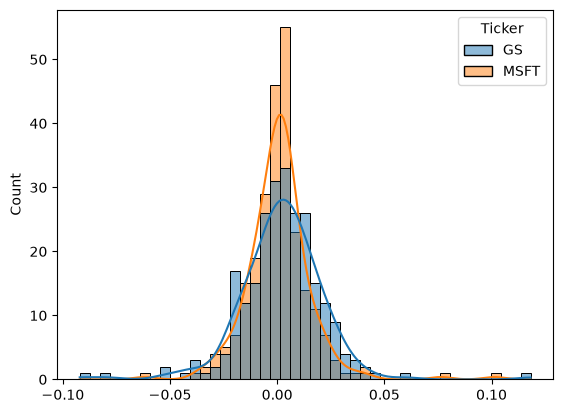

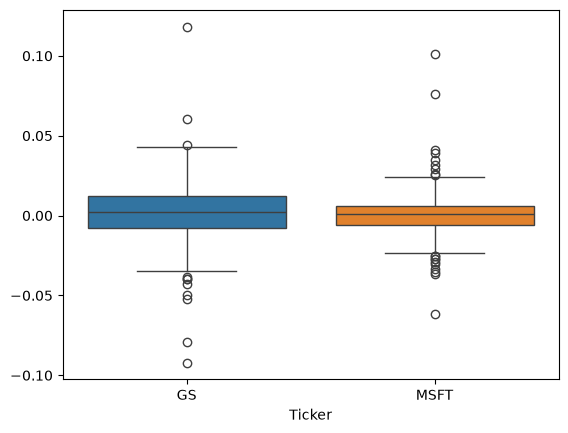

In [22]:
sns.histplot(data=returns, kde=True)
plt.show()

sns.boxplot(data=returns)
plt.show()

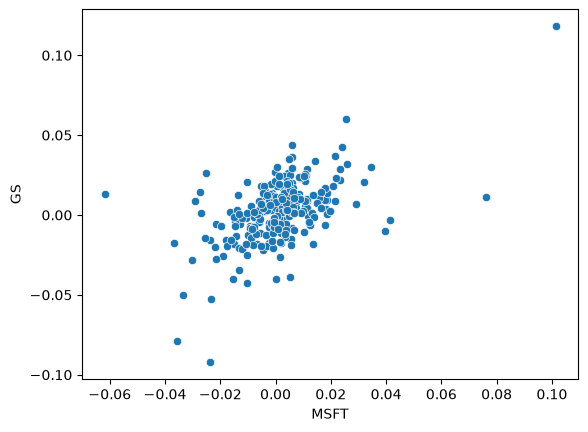

In [23]:
sns.scatterplot(data=returns, x='MSFT', y='GS')
plt.show()

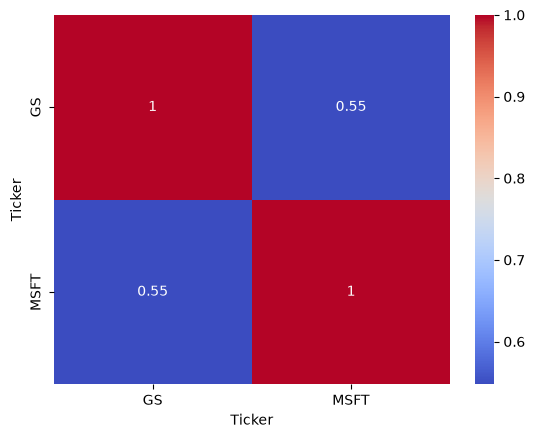

In [24]:
corr = returns.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

## PART 2

In [25]:
from scipy.stats import binom

prob_4_days = binom.pmf(k = 4, n = 5, p = 0.58)
print(prob_4_days)

0.23764641599999983


In [27]:
prob_at_least_3_days = 1 - binom.cdf(k = 2, n = 5, p = 0.58)
print(prob_at_least_3_days)

0.6474596607999998


In [28]:
n = 5
p = 0.58

mean = n * p
var = n * p * (1 - p)

print("Esperanza:", mean)
print("Varianza:", var)

Esperanza: 2.9
Varianza: 1.218


In [ ]:
import numpy as np
from scipy.stats import norm

mu = 0.0008
sigma = 0.015

In [32]:
more_than_2_half = norm.cdf(-0.025, mu, sigma)
print(more_than_2_half)

0.04271622079132892


In [34]:
profit = 1 - norm.cdf(0, mu, sigma)
print(profit)

0.5212668390867531


In [35]:
trust_95 = norm.ppf(0.05, mu, sigma)
print(trust_95)

-0.023872804404272092


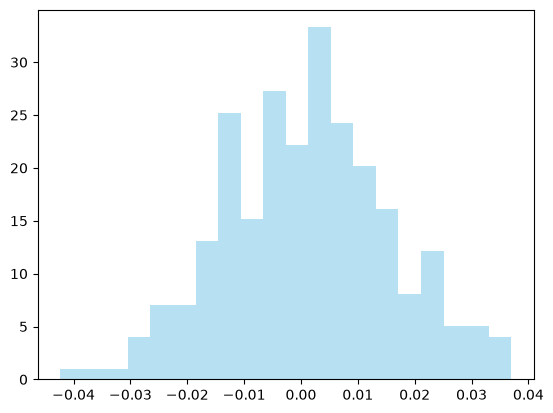

In [38]:
simulation = np.random.normal(mu, sigma, 250)

plt.hist(simulation, bins=20, density=True, alpha=0.6, color='skyblue')
plt.show()